# Human-AI Review of Fraud Alerts (FiFAR)
In a bank, the fraud model does not act alone: suspicious applications (**alerts**) are reviewed by human fraud analysts, and there are not enough analysts to check every alert. This notebook asks: **which alerts should the model decide by itself, and which should go to an analyst?**

We use the **Financial Fraud Alert Review (FiFAR)** dataset, built by Feedzai on the same Base applications as notebook 02:
- **30,622 alerts** from months 3-7: the Base applications that Feedzai's own alert model (a LightGBM) flagged
- the decision of **50 synthetic fraud analysts** on every alert
- **capacity limits**: how many alerts each analyst can review

Our frozen model from notebook 02 (XGBoost) is reused unchanged. Nothing is retrained here.

## **1. Imports**

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import roc_auc_score, average_precision_score

# Plot settings (same as notebook 02)
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Months Used**
Our model was trained on Base months 0-3, tuned on month 4 and had its threshold picked on month 5. FiFAR's alerts cover months 3-7, so:

| Months | Used for |
|---|---|
| 3 | **not used**: our model was trained on these applications, so its scores there are too optimistic |
| 4-6 | **history**: measuring how good each analyst is, and setting up the review policies |
| 7 | **test**: comparing the review policies (also FiFAR's own test month) |

Fairness uses the same age groups as notebook 02: **50+ vs under 50**.

In [2]:
DATA_DIR = '../data'
FIFAR_DIR = f'{DATA_DIR}/fifar'
TARGET = 'fraud_bool'

HISTORY_MONTHS = [4, 5, 6]
TEST_MONTHS = [7]
SEEDS = [0, 1, 2, 3, 4]

## **3. Load FiFAR**

In [3]:
alerts = pd.read_parquet(f'{FIFAR_DIR}/alert_data/processed_data/alerts.parquet')
expert_predictions = pd.read_parquet(f'{FIFAR_DIR}/synthetic_experts/expert_predictions.parquet')
ANALYSTS = list(expert_predictions.columns)

# both tables are indexed by case_id; put the analyst decisions in the same row order as the alerts
expert_predictions = expert_predictions.loc[alerts.index]

print(f'{len(alerts):,} alerts, {len(ANALYSTS)} analysts')
alerts.groupby('month').agg(alerts=(TARGET, 'size'), fraud_cases=(TARGET, 'sum'), fraud_rate=(TARGET, 'mean')).round(3)

30,622 alerts, 50 analysts


,alerts,fraud_cases,fraud_rate
month,,,
3,8282,806,0.097
4,7612,830,0.109
5,4871,665,0.137
6,5400,702,0.130
7,4457,711,0.160


In [4]:
# How the alerts were chosen: Feedzai's alert model flags every application above a fixed score
all_scores = pd.read_parquet(f'{FIFAR_DIR}/alert_data/processed_data/BAF_alert_model_score.parquet',
                             columns=[TARGET, 'model_score'])
alert_threshold = alerts['model_score'].min()
# this file has no month column; FiFAR's case_id is the row number after Base is sorted by month,
# so the case_id-th smallest month is that application's month
months_sorted = np.sort(pd.read_csv(f'{DATA_DIR}/Base.csv', usecols=['month'])['month'].to_numpy())
all_scores['month'] = months_sorted[all_scores.index]

rows = []
for month, part in all_scores.groupby('month'):
    flagged = part['model_score'] >= alert_threshold
    rows.append({'month': month, 'applications': len(part), 'alerts': flagged.sum(),
                 'FPR': flagged[part[TARGET] == 0].mean(), 'recall': flagged[part[TARGET] == 1].mean()})
print(f'Alert model threshold: {alert_threshold:.4f}')
pd.DataFrame(rows).set_index('month').round(3)

Alert model threshold: 0.0510


,applications,alerts,FPR,recall
month,,,,
3,150936,8282,0.050,0.579
4,127691,7612,0.054,0.572
5,119323,4871,0.036,0.471
6,108168,5400,0.044,0.484
7,96843,4457,0.039,0.498


**Findings**

How the numbers are derived:
- **Alert threshold.** FiFAR doesn't state the alert model's cut-off, so it is taken as the lowest `model_score` among the alerts: **0.0510**. Applying it to all 602,961 scored applications in months 3-7 gives exactly 30,622 alerts, matching the alert file month by month, so the alerts are exactly the applications scoring ≥ 0.0510.
- **FPR** = genuine applications alerted / all genuine applications; **recall** = fraud applications alerted / all fraud applications, per month. For example, in month 3: 7,476 of 149,544 genuine applications were alerted (FPR 0.050) and 806 of 1,392 fraud applications (recall 0.579).
- **Fraud rate among alerts** = fraud alerted / alerts: 3,714 / 30,622 = 12.1% overall, from 806 / 8,282 = 9.7% in month 3 to 711 / 4,457 = 16.0% in month 7.

What they show:
- **About 12% of alerts are fraud**, against 1.1% of all Base applications (11,029 of 1,000,000), so an alert is about 10-11x more likely to be fraud than a typical application.
- **Analysts only ever see a small, high-risk slice.** Alerts are 4-6% of each month's applications, so everything in this notebook is about the alerts only.
- **About half of all fraud never reaches an analyst.** Recall is 0.47-0.58, so 42-53% of fraud is missed at the alert stage and no review policy can recover it. This caps what any human-AI setup here can catch.
- **The fixed threshold drifts.** With the cut-off fixed at 0.0510, FPR falls from 5.0% (month 3) to 3.9% (month 7) and recall from 0.58 to 0.50: the screen gets stricter and catches less fraud over time, the same drift seen in notebook 02.

### **3.1 Link the Alerts to Our Base Rows**
FiFAR's `case_id` is not the row number in our `Base.csv`. We check the link by matching every alert to a Base row on several feature values, so the alerts are known to be the same applications our model was built on.

In [5]:
base = pd.read_csv(f'{DATA_DIR}/Base.csv')

KEY = ['name_email_similarity', 'velocity_6h', 'credit_risk_score', 'customer_age', 'month']
# rounded, because the two files store some decimals with tiny differences
left = alerts[KEY].round(6).reset_index()
right = base[KEY].round(6).reset_index(names='row_id')
link = left.merge(right, on=KEY, how='left').set_index('case_id')

print(f"{link['row_id'].notna().sum():,} of {len(alerts):,} alerts matched to a Base row, "
      f"{link.index.duplicated().sum()} matched twice")
alerts['row_id'] = link.loc[alerts.index, 'row_id'].astype(int)

30,622 of 30,622 alerts matched to a Base row, 0 matched twice


## **4. Score the Alerts with Our Model**
The features are built exactly as in notebook 02. `preprocess` and `make_features` below are **copies** of notebook 02 (sections 3 and 4.2); if those change, update them here too.

In [6]:
MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']


def preprocess(df, missing_flags=True):
    """Copied from notebook 02, section 3."""
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    """Copied from notebook 02, section 4.2."""
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])

In [7]:
final_model = json.load(open('../configs/final_model.json'))
thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}

# FiFAR adds model_score (Feedzai's alert model) and row_id (ours); neither is one of our features
X_alerts = make_features(alerts.drop(columns=['model_score', 'row_id']), **final_model['features'])

scores = {}
for seed in SEEDS:
    model = joblib.load(f"../outputs/models/{final_model['model']}_seed{seed}.joblib")
    scores[seed] = model.predict_proba(X_alerts)[:, 1]
    alerts[f'score_seed{seed}'] = scores[seed]

# Check: on months 6-7 our scores should equal the seed-0 test scores saved by notebook 02
saved = pd.read_csv('../outputs/predictions/base_test_seed0.csv').set_index('row_id')['score']
in_test = alerts['month'].isin([6, 7])
difference = np.abs(alerts.loc[in_test, 'score_seed0'].to_numpy() - saved.loc[alerts.loc[in_test, 'row_id']].to_numpy())
print(f'Largest difference from the saved notebook-02 scores: {difference.max():.2e}')

Largest difference from the saved notebook-02 scores: 2.98e-08


### **4.1 How Well Our Model Ranks the Alerts**
Every alert already looked suspicious to Feedzai's model, so separating fraud from genuine is harder here than on all applications. We compare our model with Feedzai's alert score on the same alerts. "Flagged" uses our frozen month-5 threshold, which was set to flag 5% of *all* genuine applications, so it flags far more of these riskier alerts.

In [8]:
def model_metrics(y_true, score, threshold):
    y_true = np.asarray(y_true)
    flagged = np.asarray(score) >= threshold
    return {
        'ROC-AUC': roc_auc_score(y_true, score),
        'PR-AUC': average_precision_score(y_true, score),
        'share flagged': flagged.mean(),
        'recall at threshold': flagged[y_true == 1].mean(),
        'FPR at threshold': flagged[y_true == 0].mean(),
    }


rows = []
for months, label in [(HISTORY_MONTHS, 'history (4-6)'), (TEST_MONTHS, 'test (7)')]:
    part = alerts[alerts['month'].isin(months)]
    for seed in SEEDS:
        rows.append({'months': label, 'scorer': 'our XGBoost', 'seed': seed,
                     **model_metrics(part[TARGET], part[f'score_seed{seed}'], thresholds[seed])})
    rows.append({'months': label, 'scorer': 'Feedzai alert model', 'seed': None,
                 'ROC-AUC': roc_auc_score(part[TARGET], part['model_score']),
                 'PR-AUC': average_precision_score(part[TARGET], part['model_score'])})

alert_model_table = pd.DataFrame(rows).drop(columns='seed').groupby(['months', 'scorer'], sort=False).mean()
alert_model_table.round(3)

ROC-AUC  PR-AUC  share flagged  \
months        scorer                                                
history (4-6) our XGBoost            0.704   0.292          0.885   
              Feedzai alert model    0.682   0.276            NaN   
test (7)      our XGBoost            0.713   0.352          0.809   
              Feedzai alert model    0.675   0.328            NaN   

                                   recall at threshold  FPR at threshold  
months        scorer                                                      
history (4-6) our XGBoost                        0.966             0.874  
              Feedzai alert model                  NaN               NaN  
test (7)      our XGBoost                        0.943             0.784  
              Feedzai alert model                  NaN               NaN

**Findings**
- **Our model ranks alerts slightly better than Feedzai's alert model**, in both periods and on both measures (ROC-AUC 0.70-0.71 vs 0.68; PR-AUC 0.29-0.35 vs 0.28-0.33). The gap is small. For PR-AUC, random guessing would score the fraud rate among alerts (about 0.12 on history, 0.16 on test), so both models are only about 2-2.5x better than random.
- **Fraud is much harder to spot among alerts than among all applications.** Our model's ROC-AUC falls from 0.89 on all Base test applications (notebook 02) to about 0.71 here. That is expected: the easy genuine cases were already filtered out by the alert model, and what is left all looks suspicious.
- **The frozen threshold is useless as a decision rule on alerts.** It was set to flag 5% of *all* genuine applications in month 5, but alerts are all risky, so it flags 81-89% of them and wrongly flags 78-87% of genuine alerts. For the model to make decisions in the review simulation, it needs a new threshold chosen on the history months, judged on recall and FPR rather than accuracy.
- **This is why human review is worth studying.** On the history alerts, every one of the 50 analysts catches more fraud than our model would at the same FPR. For example, `standard#38` catches 78% of fraud while wrongly flagging 1.2% of genuine alerts; at that FPR our model catches only 9%.

## **5. Profile the Analysts**
Each analyst's decisions on the **history months (4-6)** only, so that nothing about month 7 is used when the review policies later pick analysts. For each analyst:
- **accuracy**, **recall** (share of fraud they catch) and **FPR** (share of genuine applicants they wrongly flag)
- FPR for each age group, and **predictive equality** (lower group FPR / higher group FPR, 1 = equal), as in notebook 02
- how often they **agree** with our model (seed 0, frozen threshold)

Our model is shown on the same alerts for comparison.

In [9]:
history = alerts['month'].isin(HISTORY_MONTHS)
y_history = alerts.loc[history, TARGET].to_numpy()
age_50_plus = alerts.loc[history, 'customer_age'].to_numpy() >= 50
model_flags = alerts.loc[history, 'score_seed0'].to_numpy() >= thresholds[0]


def decision_metrics(decisions, y_true, is_50_plus):
    decisions = np.asarray(decisions).astype(bool)
    fraud = y_true == 1
    genuine = y_true == 0
    fpr_50_plus = decisions[genuine & is_50_plus].mean()
    fpr_under_50 = decisions[genuine & ~is_50_plus].mean()
    return {
        'accuracy': (decisions == fraud).mean(),
        'recall': decisions[fraud].mean(),
        'FPR': decisions[genuine].mean(),
        'FPR 50+': fpr_50_plus,
        'FPR under 50': fpr_under_50,
        'predictive equality': min(fpr_50_plus, fpr_under_50) / max(fpr_50_plus, fpr_under_50),
    }


rows = []
for analyst in ANALYSTS:
    decisions = expert_predictions.loc[history, analyst].to_numpy()
    rows.append({'analyst': analyst, **decision_metrics(decisions, y_history, age_50_plus),
                 'agrees with model': (decisions.astype(bool) == model_flags).mean()})
analyst_profile = pd.DataFrame(rows).set_index('analyst')

our_model = pd.Series(decision_metrics(model_flags, y_history, age_50_plus), name='our model (seed 0)')
summary = analyst_profile.describe().loc[['mean', 'min', '25%', '50%', '75%', 'max']]
pd.concat([summary, our_model.to_frame().T]).round(3)

,accuracy,recall,FPR,FPR 50+,FPR under 50,predictive equality,agrees with model
mean,0.719,0.832,0.297,0.326,0.276,0.792,0.440
min,0.345,0.662,0.012,0.016,0.009,0.539,0.216
25%,0.599,0.756,0.125,0.154,0.106,0.698,0.312
50%,0.726,0.832,0.287,0.319,0.263,0.811,0.432
75%,0.862,0.901,0.444,0.482,0.416,0.877,0.561
max,0.962,0.985,0.744,0.776,0.721,0.967,0.766
our model (seed 0),0.228,0.968,0.876,0.905,0.854,0.943,NaN


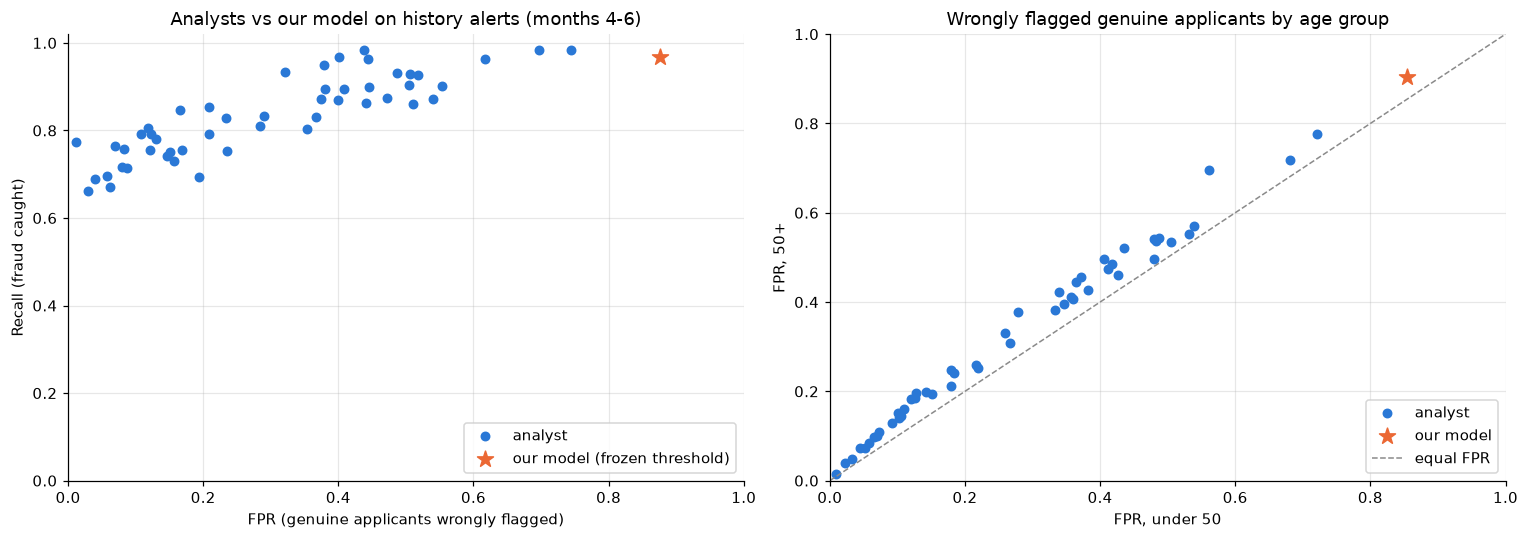

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: each analyst's recall and FPR, with our model's threshold for comparison
ax = axes[0]
ax.scatter(analyst_profile['FPR'], analyst_profile['recall'], color=BLUE, s=30, label='analyst')
ax.scatter(our_model['FPR'], our_model['recall'], color=ORANGE, s=120, marker='*', label='our model (frozen threshold)')
ax.set_xlabel('FPR (genuine applicants wrongly flagged)')
ax.set_ylabel('Recall (fraud caught)')
ax.set_title('Analysts vs our model on history alerts (months 4-6)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc='lower right')

# Right: FPR for each age group; points above the line flag older applicants more often
ax = axes[1]
ax.scatter(analyst_profile['FPR under 50'], analyst_profile['FPR 50+'], color=BLUE, s=30, label='analyst')
ax.scatter(our_model['FPR under 50'], our_model['FPR 50+'], color=ORANGE, s=120, marker='*', label='our model')
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1, label='equal FPR')
ax.set_xlabel('FPR, under 50')
ax.set_ylabel('FPR, 50+')
ax.set_title('Wrongly flagged genuine applicants by age group')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [11]:
# The 5 most and least accurate analysts
pd.concat([analyst_profile.sort_values('accuracy', ascending=False).head(5),
           analyst_profile.sort_values('accuracy').head(5)]).round(3)

,accuracy,recall,FPR,FPR 50+,FPR under 50,predictive equality,agrees with model
analyst,,,,,,,
standard#38,0.962,0.775,0.012,0.016,0.009,0.539,0.216
standard#33,0.933,0.662,0.029,0.040,0.022,0.551,0.217
standard#25,0.927,0.690,0.040,0.048,0.034,0.694,0.228
standard#23,0.912,0.696,0.057,0.074,0.045,0.608,0.243
standard#39,0.910,0.765,0.069,0.085,0.058,0.676,0.262
standard#4,0.345,0.983,0.744,0.776,0.721,0.929,0.766
standard#3,0.387,0.983,0.697,0.718,0.681,0.948,0.734
standard#32,0.454,0.964,0.618,0.695,0.561,0.806,0.688
standard#42,0.503,0.901,0.553,0.571,0.539,0.944,0.618


**Findings**

- **The analysts differ hugely.** On the history alerts, recall ranges from 0.66 to 0.98 and FPR from 1% to 74%. The careful ones (e.g. `standard#38`: FPR 1%, recall 0.78) and the trigger-happy ones (e.g. `standard#4`: flags 74% of genuine alerts, recall 0.98) make very different trade-offs, so *which* analyst gets a case matters, not just *whether* a human sees it.
- **Accuracy alone is misleading here.** Only 12-16% of alerts are fraud, so calling every alert genuine would already score about 0.87 accuracy, and many analysts score below that. Recall, FPR and, later, cost are the useful measures.
- **Every analyst flags older applicants more often.** All 50 have a higher FPR for 50+ than for under 50 (predictive equality 0.54-0.97, mean 0.79). The most accurate analysts are among the most age-biased (`standard#38`: 0.54, `standard#33`: 0.55), so routing cases to the "best" analyst could make age disparities worse. This is the fairness question for the routing policies.
- **Our model's frozen threshold doesn't suit alerts.** It was set to flag 5% of *all* genuine applications, but every alert already looks risky, so it flags 81-89% of alerts (FPR 0.87 on history). The review policies therefore need a threshold chosen for alerts, picked on the history months.
- **Our model still ranks alerts slightly better than Feedzai's alert model** (ROC-AUC 0.70-0.71 vs 0.68; PR-AUC 0.29-0.35 vs 0.28-0.33), but separating fraud among alerts is much harder than among all applications (ROC-AUC 0.89 in notebook 02). The best analysts beat the model within alerts, which is what makes human review worth simulating.